# American Sign Language (ASL) Letter Classification

**Name:** Abdelrahman Ali

##Problem Statement:
###The project focuses on developing an image classification model to recognize American Sign Language (ASL) hand signs from single images.

###Using the Sign Language MNIST dataset, a Convolutional Neural Network (CNN) will be built from scratch to classify $28 \times 28$ grayscale images into 24 ASL alphabet letters (excluding 'J' and 'Z' due to their requirement for movement).

##Objective:
###The primary goal is to establish a reliable foundation for a future real-time fingerspelling recognition system capable of combining individually recognized letters into complete words and sentences.



In [37]:
!pip install -q kaggle

import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter Kaggle API token: ")

!kaggle datasets download -d datamunge/sign-language-mnist

!unzip -qo sign-language-mnist.zip -d /content/sign_language_mnist



Enter Kaggle API token: ··········
Dataset URL: https://www.kaggle.com/datasets/datamunge/sign-language-mnist
License(s): CC0-1.0
sign-language-mnist.zip: Skipping, found more recently modified local copy (use --force to force download)


## Import Libiraries

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import os
import random

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import (
 BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    Input,
    MaxPooling2D)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


In [39]:

print(os.listdir("/content/sign_language_mnist"))

['american_sign_language.PNG', 'amer_sign2.png', 'sign_mnist_test', 'sign_mnist_train', 'amer_sign3.png', 'sign_mnist_train.csv', 'sign_mnist_test.csv']


### EDA

In [40]:
train_df = pd.read_csv("/content/sign_language_mnist/sign_mnist_train.csv")
test_df = pd.read_csv("/content/sign_language_mnist/sign_mnist_test.csv")
print('Train Shape',train_df.shape)
print('Test Shape',test_df.shape)

Train Shape (27455, 785)
Test Shape (7172, 785)


In [ ]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [ ]:
print('Data Train info')
train_df.info()
print('Data Test info')
test_df.info()


Data Train info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27455 entries, 0 to 27454
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 164.4 MB
Data Test info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7172 entries, 0 to 7171
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 43.0 MB


### Check missing values

In [ ]:
print("Missing values in train:", train_df.isnull().sum().sum())
print("Missing values in test :", test_df.isnull().sum().sum())

Missing values in train: 0
Missing values in test : 0


### Classes

In [41]:
labels = sorted(train_df['label'].unique())
print('Number of classes',len(labels))
print('labels',labels)


Number of classes 24
labels [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


### Convert Labels into letters (Mapping)

In [42]:
label_to_letter = {
    0: 'A',
    1: 'B',
    2: 'C',
    3: 'D',
    4: 'E',
    5: 'F',
    6: 'G',
    7: 'H',
    8: 'I',
    10: 'K',
    11: 'L',
    12: 'M',
    13: 'N',
    14: 'O',
    15: 'P',
    16: 'Q',
    17: 'R',
    18: 'S',
    19: 'T',
    20: 'U',
    21: 'V',
    22: 'W',
    23: 'X',
    24: 'Y'
}

print(label_to_letter)

{0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 10: 'K', 11: 'L', 12: 'M', 13: 'N', 14: 'O', 15: 'P', 16: 'Q', 17: 'R', 18: 'S', 19: 'T', 20: 'U', 21: 'V', 22: 'W', 23: 'X', 24: 'Y'}


###  The numbers 9 and 25 aren't there because they represent J and Z and they're excluded from the dataset.

###  Split labels from pixles

In [43]:
x = train_df.drop('label',axis=1)
y = train_df['label']

x_test = test_df.drop('label',axis=1)
y_test = test_df['label']


print('x  train shape',x.shape)
print('y  train shape',y.shape)
print('x_test shape',x_test.shape)
print('y_test shape',y_test.shape)

x  train shape (27455, 784)
y  train shape (27455,)
x_test shape (7172, 784)
y_test shape (7172,)


### x= images , y = labels

### Convert Frist image to 28x28

In [44]:
image = x.iloc[0].values.reshape(28,28)
print(image.shape)


(28, 28)


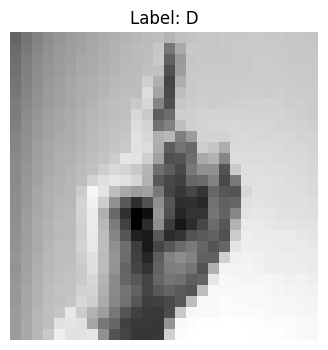

In [8]:
plt.figure(figsize=(4, 4))

plt.imshow(image, cmap="gray")
plt.title(f"Label: {label_to_letter[y[0]]}")
plt.axis("off")

plt.show()

### Display first 16 Images

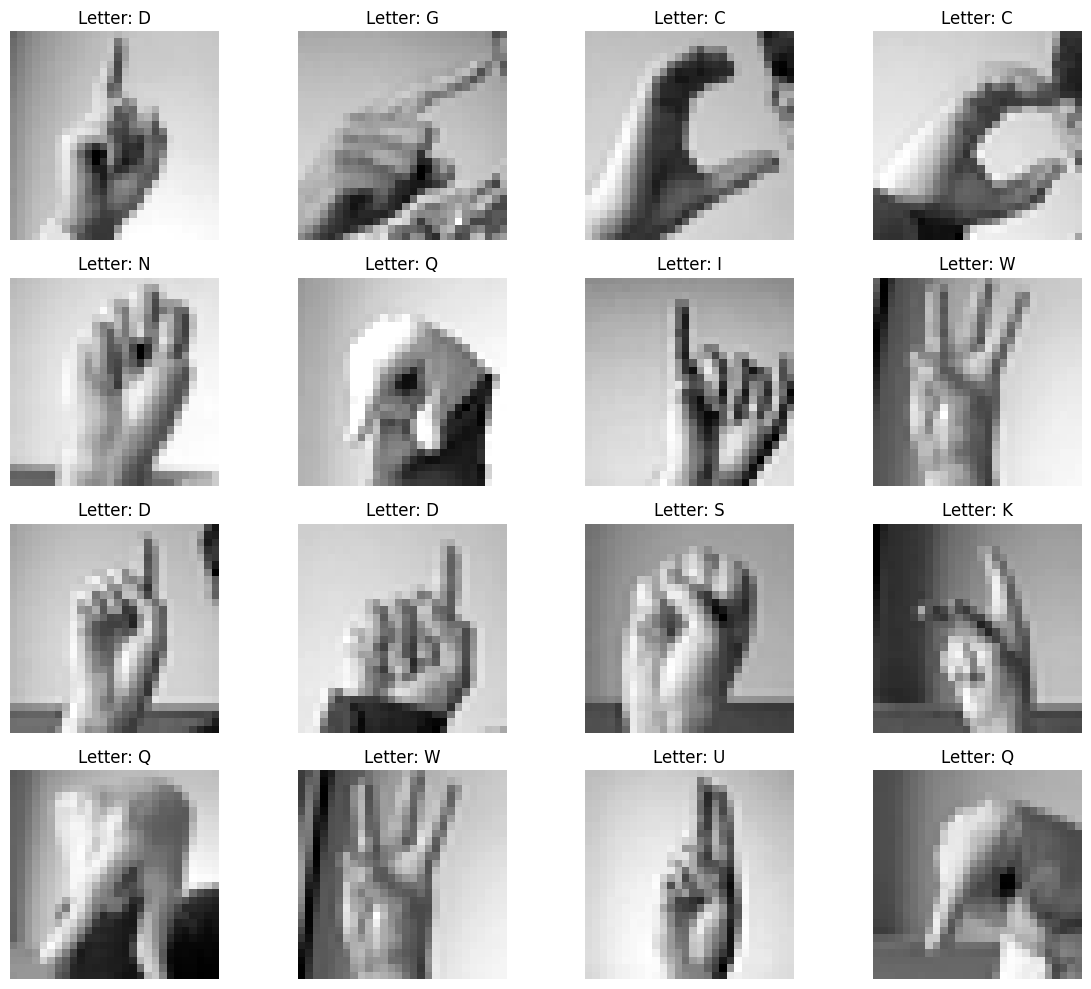

In [13]:
plt.figure(figsize=(12, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    image = x.iloc[i].values.reshape(28, 28)
    plt.imshow(image, cmap="gray")

    letter = label_to_letter[y[i]]
    plt.title(f"Letter: {letter}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Class Distribution

In [45]:
class_counts = train_df['label'].value_counts().sort_index()
class_distribution = pd.DataFrame({
    'label' : class_counts.index,
    'letter' : [label_to_letter[label] for label in class_counts.index],
    'count' : class_counts.values
})

print(class_distribution)

    label letter  count
0       0      A   1126
1       1      B   1010
2       2      C   1144
3       3      D   1196
4       4      E    957
5       5      F   1204
6       6      G   1090
7       7      H   1013
8       8      I   1162
9      10      K   1114
10     11      L   1241
11     12      M   1055
12     13      N   1151
13     14      O   1196
14     15      P   1088
15     16      Q   1279
16     17      R   1294
17     18      S   1199
18     19      T   1186
19     20      U   1161
20     21      V   1082
21     22      W   1225
22     23      X   1164
23     24      Y   1118


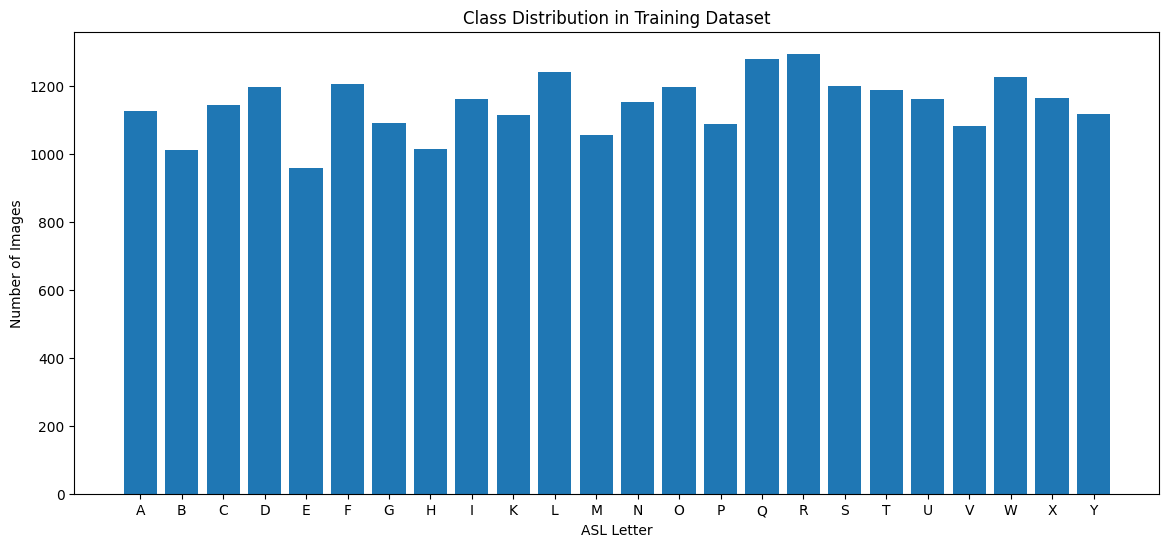

In [17]:
plt.figure(figsize=(14, 6))

plt.bar(
    class_distribution["letter"],
    class_distribution["count"]
)

plt.title("Class Distribution in Training Dataset")
plt.xlabel("ASL Letter")
plt.ylabel("Number of Images")

plt.show()

In [46]:
test_labels = test_df['label'].sort_values().unique()
print('num of test classes',len(test_labels))
print('test classes',test_labels)

num of test classes 24
test classes [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [47]:
test_class_count = test_df['label'].value_counts().sort_index()
test_class_distribution = pd.DataFrame({
    'label' : test_class_count.index,
    'letter' : [label_to_letter[label] for label in test_class_count.index],
    'count' : test_class_count.values
})

print(test_class_distribution)

    label letter  count
0       0      A    331
1       1      B    432
2       2      C    310
3       3      D    245
4       4      E    498
5       5      F    247
6       6      G    348
7       7      H    436
8       8      I    288
9      10      K    331
10     11      L    209
11     12      M    394
12     13      N    291
13     14      O    246
14     15      P    347
15     16      Q    164
16     17      R    144
17     18      S    246
18     19      T    248
19     20      U    266
20     21      V    346
21     22      W    206
22     23      X    267
23     24      Y    332


### Random Images

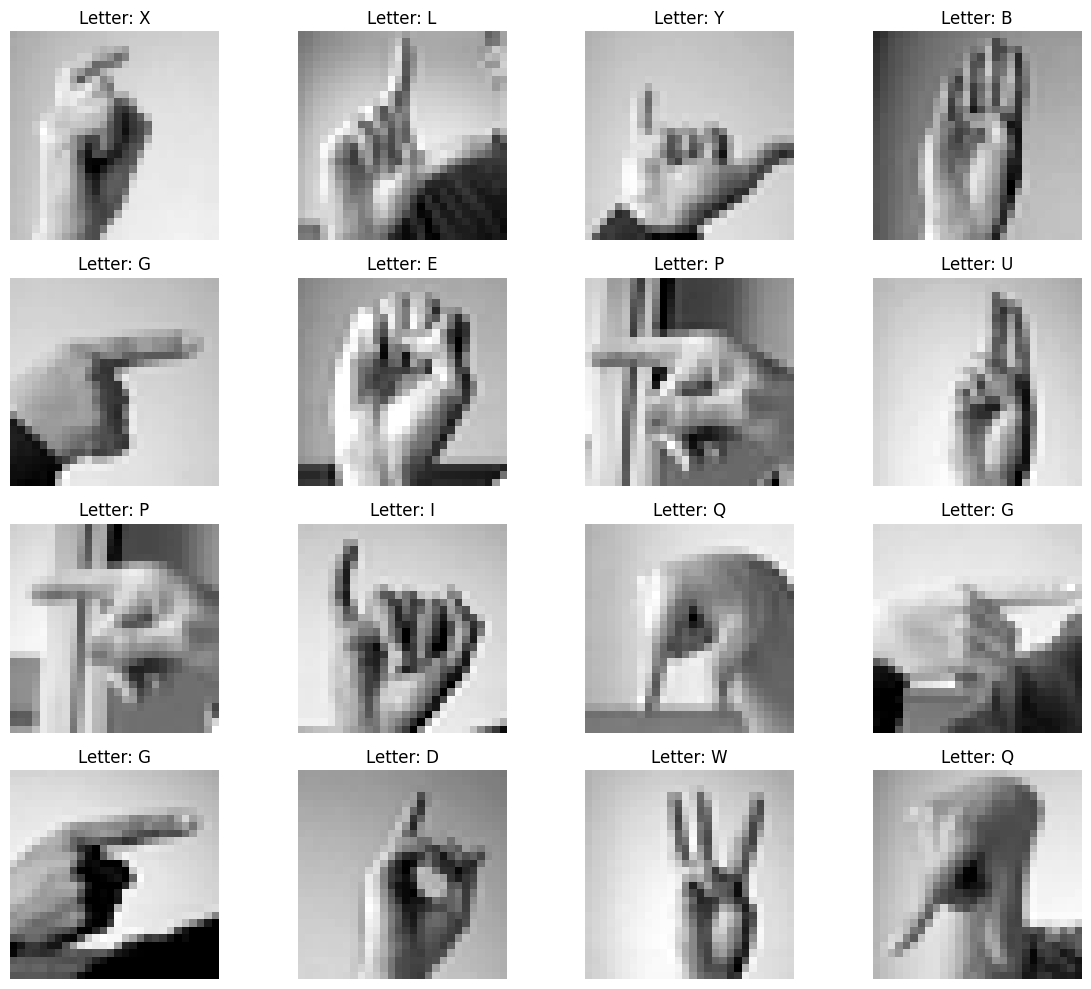

In [27]:
random_indices = np.random.choice(len(x), 16, replace=False)

plt.figure(figsize=(12, 10))

for i, idx in enumerate(random_indices):
    plt.subplot(4, 4, i + 1)

    image = x.iloc[idx].values.reshape(28, 28)
    plt.imshow(image, cmap="gray")

    letter = label_to_letter[y[idx]]
    plt.title(f"Letter: {letter}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Preprocessing

In [48]:
x = x.values.reshape(-1,28,28,1)
x_test = x_test.values.reshape(-1,28,28,1)

print('x train shape',x.shape)
print('x test shape',x_test.shape)

x train shape (27455, 28, 28, 1)
x test shape (7172, 28, 28, 1)


### Normalization

In [49]:
x = x.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0
print('min value pixel',x.min())
print('max value pixel',x.max())

min value pixel 0.0
max value pixel 1.0


### Validation Training Split

In [50]:
x_train, x_val, y_train, y_val = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)
print('x_train shape',x_train.shape,y_train.shape)
print('x_val shape',x_val.shape,y_val.shape)
print('x_test shape',x_test.shape,y_test.shape)

x_train shape (21964, 28, 28, 1) (21964,)
x_val shape (5491, 28, 28, 1) (5491,)
x_test shape (7172, 28, 28, 1) (7172,)


### Data Augmentation

In [57]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.08),
    layers.RandomTranslation(0.08, 0.08)
],name = 'data_augmentation')

## Build CNN

In [59]:
model = keras.Sequential([
    Input(shape=(28,28,1)),
    data_augmentation,
    Conv2D(32,(3,3),activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(64,(3,3),activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128,(3,3),activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Dropout(0.3),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.4),

    Dense(24,activation='softmax')

]

)

### Summary

In [60]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,176 (442.09 KB)

 Trainable params: 112,728 (440.34 KB)

 Non-trainable params: 448 (1.75 KB)

## Compile

In [63]:
model.compile(
    optimizer= keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Rencodind

### We re-encode the original labels because the dataset contains 24 classes but their original numeric labels are not continuous due to the excluded J and Z classes. We map them to consecutive indices from 0 to 23 so they match the 24 output neurons of the CNN.

In [64]:
label_mapping = {
    original_label : new_label
    for new_label, original_label in enumerate(sorted(train_df['label'].unique()))
}

print(label_mapping)


{np.int64(0): 0, np.int64(1): 1, np.int64(2): 2, np.int64(3): 3, np.int64(4): 4, np.int64(5): 5, np.int64(6): 6, np.int64(7): 7, np.int64(8): 8, np.int64(10): 9, np.int64(11): 10, np.int64(12): 11, np.int64(13): 12, np.int64(14): 13, np.int64(15): 14, np.int64(16): 15, np.int64(17): 16, np.int64(18): 17, np.int64(19): 18, np.int64(20): 19, np.int64(21): 20, np.int64(22): 21, np.int64(23): 22, np.int64(24): 23}


In [66]:
y_train_encoded = np.array([
    label_mapping[original_label]
    for original_label in y_train
])

y_val_encoded = np.array([
    label_mapping[original_label]
    for original_label in y_val
])

y_test_encoded = np.array([
    label_mapping[original_label]
    for original_label in y_test
])
print('encoded train labels',np.unique(y_train_encoded))
print('encoded val labels',np.unique(y_val_encoded))
print('encoded test labels',np.unique(y_test_encoded))

encoded train labels [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
encoded val labels [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
encoded test labels [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


## Callbacks

In [67]:
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights = True
)
model_checkpoint = ModelCheckpoint(
    "/content/best_asl_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)


### Training

In [69]:
history = model.fit(
    x_train,
    y_train_encoded,
    validation_data=(x_val,y_val_encoded),
    epochs=30,
    batch_size=64,
    callbacks = [early_stopping,model_checkpoint],
    verbose=1

)

Epoch 1/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2488 - loss: 2.6332
Epoch 1: val_loss improved from None to 3.33254, saving model to /content/best_asl_cnn.keras

Epoch 1: finished saving model to /content/best_asl_cnn.keras
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.3894 - loss: 1.9891 - val_accuracy: 0.1635 - val_loss: 3.3325
Epoch 2/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6681 - loss: 0.9965
Epoch 2: val_loss improved from 3.33254 to 0.40961, saving model to /content/best_asl_cnn.keras

Epoch 2: finished saving model to /content/best_asl_cnn.keras
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7053 - loss: 0.8777 - val_accuracy: 0.8629 - val_loss: 0.4096
Epoch 3/30
342/344 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7867 - loss: 0.6286
Epoch 3: val_loss improved from 0.40961 to 0.18100, saving model to /content/best_asl_cnn.keras

Epoch 3: finished saving model to /content/best_asl_cnn.keras
344/344 ━━━━━━━━━━━━━━━━━━━━

In [70]:
best_model = keras.models.load_model("/content/best_asl_cnn.keras")

### Accuracy

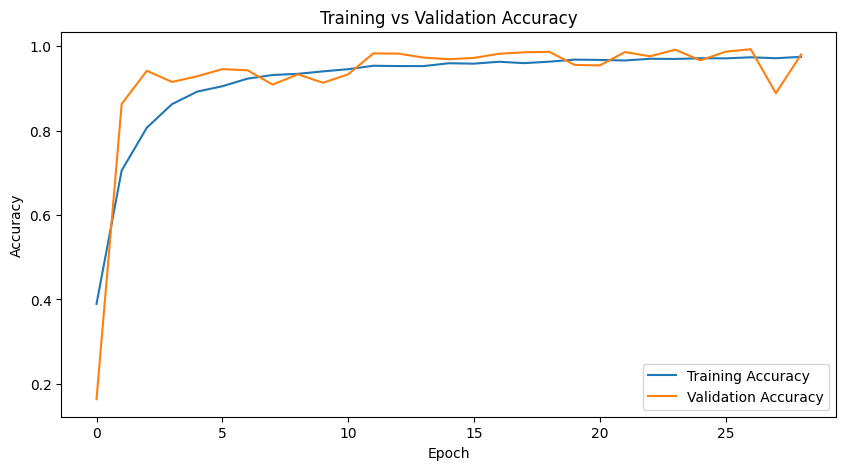

In [71]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

### Loss

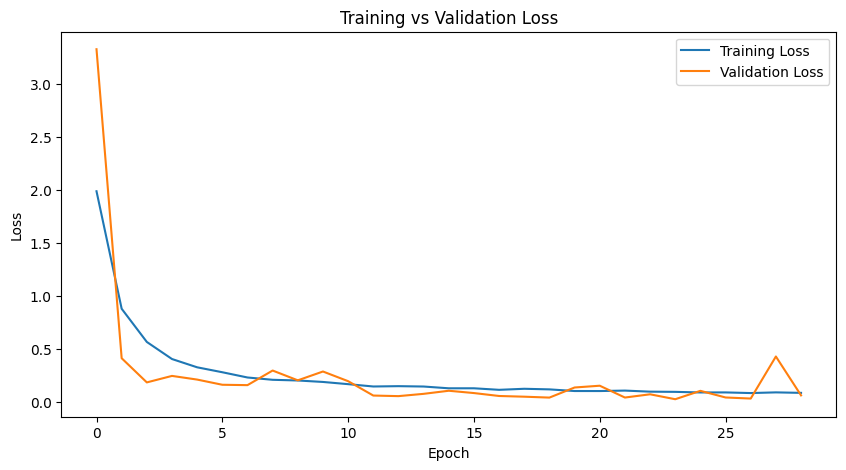

In [72]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Test

In [73]:
test_loss, test_accuracy = best_model.evaluate(x_test,y_test_encoded)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9647 - loss: 0.1362
Test Loss: 0.1362
Test Accuracy: 0.9647


### Predictions

In [74]:
y_pred_prob = best_model.predict(x_test)
y_pred_encoded = np.argmax(y_pred_prob, axis=1)
print('predection shape',y_pred_encoded.shape)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
predection shape (7172,)


### Classification Report

In [77]:
target_names = [
    label_to_letter[label]
    for label in labels
]

print(
    classification_report(
        y_test_encoded,
        y_pred_encoded,
        target_names=target_names,
        digits=4
    )
)

              precision    recall  f1-score   support

           A     0.9909    0.9879    0.9894       331
           B     0.9954    1.0000    0.9977       432
           C     0.9366    1.0000    0.9672       310
           D     0.9333    0.8571    0.8936       245
           E     0.9920    1.0000    0.9960       498
           F     1.0000    1.0000    1.0000       247
           G     0.9379    0.8678    0.9015       348
           H     0.9927    0.9312    0.9609       436
           I     0.9351    1.0000    0.9664       288
           K     1.0000    0.9245    0.9608       331
           L     0.8566    1.0000    0.9227       209
           M     0.9540    1.0000    0.9765       394
           N     0.9963    0.9244    0.9590       291
           O     1.0000    0.9065    0.9510       246
           P     0.9886    1.0000    0.9943       347
           Q     0.8586    1.0000    0.9239       164
           R     0.9600    1.0000    0.9796       144
           S     0.9800    

### Confusion Matrix

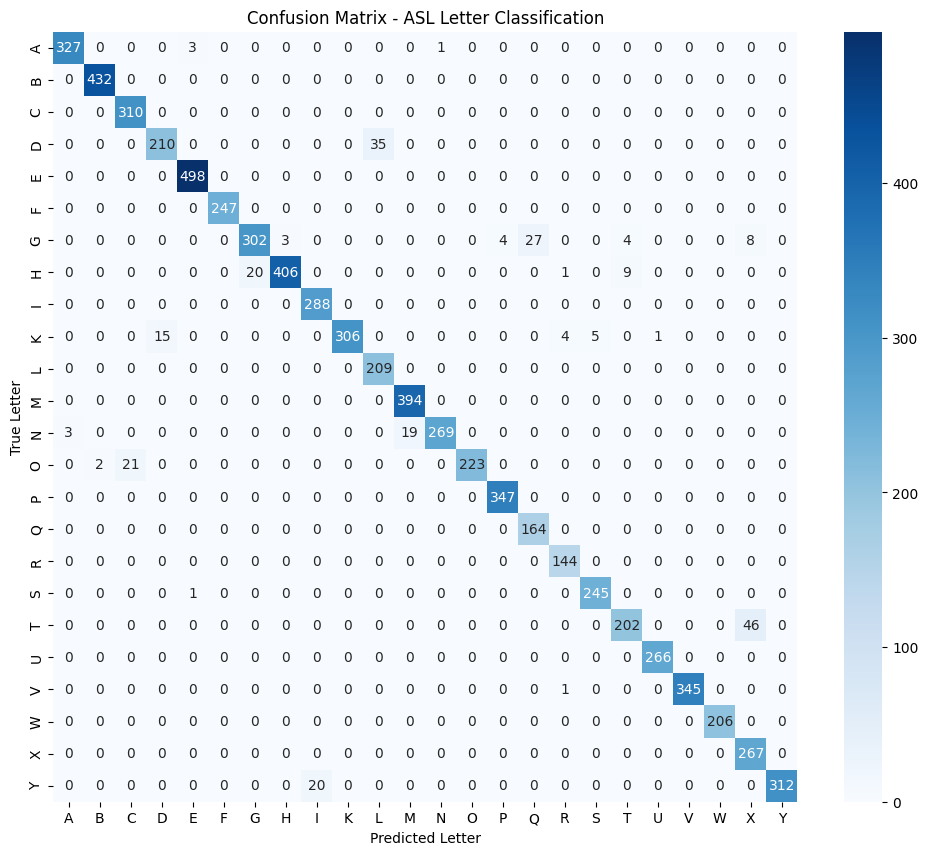

In [78]:
cm = confusion_matrix(
    y_test_encoded,
    y_pred_encoded
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title("Confusion Matrix - ASL Letter Classification")
plt.xlabel("Predicted Letter")
plt.ylabel("True Letter")

plt.show()

### Erros

In [79]:
confusion_pairs = []

for true_class in range(len(target_names)):
    for predicted_class in range(len(target_names)):

        if true_class != predicted_class and cm[true_class, predicted_class] > 0:
            confusion_pairs.append(
                (
                    target_names[true_class],
                    target_names[predicted_class],
                    cm[true_class, predicted_class]
                )
            )

confusion_pairs = sorted(
    confusion_pairs,
    key=lambda x: x[2],
    reverse=True
)

print("Top 15 Confusion Pairs:\n")

for true_letter, predicted_letter, count in confusion_pairs[:15]:
    print(
        f"True: {true_letter} → Predicted: {predicted_letter} | Errors: {count}"
    )

Top 15 Confusion Pairs:

True: T → Predicted: X | Errors: 46
True: D → Predicted: L | Errors: 35
True: G → Predicted: Q | Errors: 27
True: O → Predicted: C | Errors: 21
True: H → Predicted: G | Errors: 20
True: Y → Predicted: I | Errors: 20
True: N → Predicted: M | Errors: 19
True: K → Predicted: D | Errors: 15
True: H → Predicted: T | Errors: 9
True: G → Predicted: X | Errors: 8
True: K → Predicted: S | Errors: 5
True: G → Predicted: P | Errors: 4
True: G → Predicted: T | Errors: 4
True: K → Predicted: R | Errors: 4
True: A → Predicted: E | Errors: 3


#### The most frequent confusion was between T and X. This may be caused by similarities in finger positioning and the overall hand silhouette, especially at the low 28×28 image resolution.

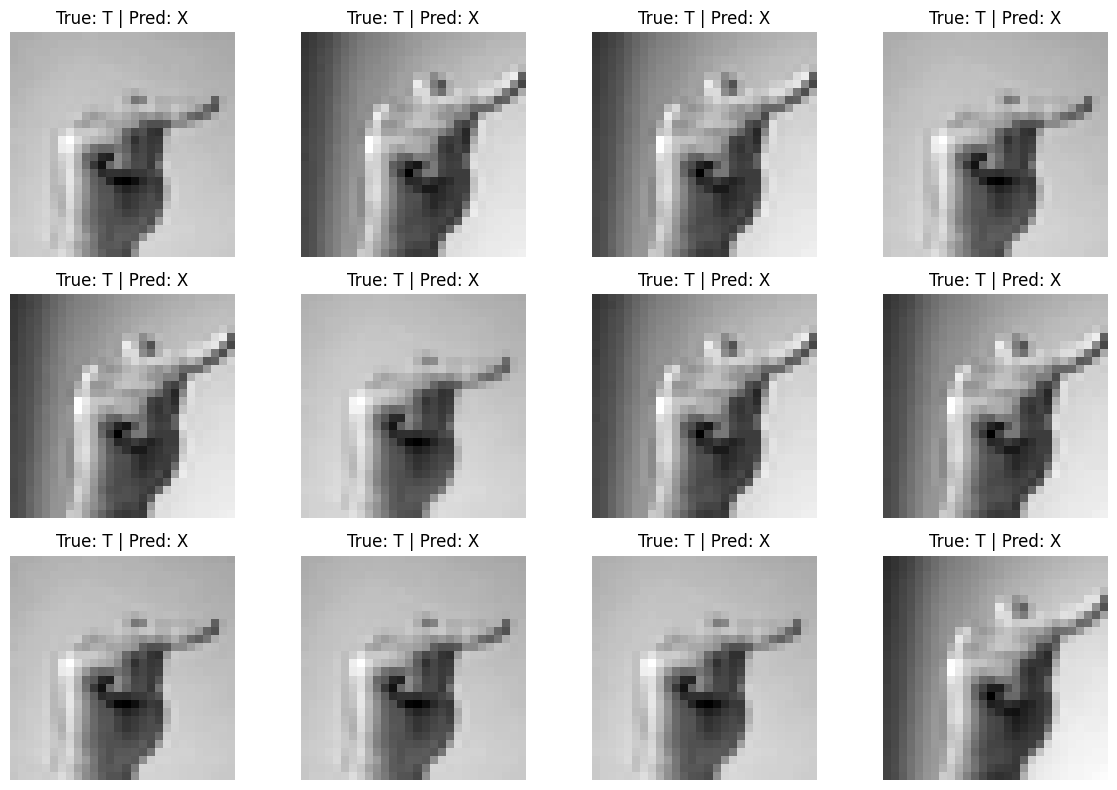

In [82]:
plt.figure(figsize=(12, 8))

for i, idx in enumerate(error_indices[:12]):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title("True: T | Pred: X")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Best , Worst Latters

In [85]:
report = classification_report(
    y_test_encoded,
    y_pred_encoded,
    target_names=target_names,
    output_dict=True
)

class_performance = pd.DataFrame(report).T

class_performance = class_performance.loc[
    target_names,
    ["precision", "recall", "f1-score"]
]

print("Best performing classes:")
display(
    class_performance.sort_values("f1-score", ascending=False).head(5)
)

print("\nLowest performing classes:")
display(
    class_performance.sort_values("f1-score").head(5)
)

Best performing classes:


,precision,recall,f1-score
F,1.000000,1.00000,1.000000
W,1.000000,1.00000,1.000000
V,1.000000,0.99711,0.998553
U,0.996255,1.00000,0.998124
B,0.995392,1.00000,0.997691



Lowest performing classes:


,precision,recall,f1-score
T,0.939535,0.814516,0.872570
D,0.933333,0.857143,0.893617
G,0.937888,0.867816,0.901493
X,0.831776,1.000000,0.908163
L,0.856557,1.000000,0.922737


### Save

In [86]:
best_model.save("/content/asl_cnn_final.keras")

print("Model saved successfully!")

Model saved successfully!


###Overall Performance: The custom CNN achieved a test accuracy of 96.47% and a macro F1-score of 96.15% on the Sign Language MNIST test set, demonstrating strong and balanced performance across all 24 ASL classes.

###Key Strengths:

####The 3-block CNN architecture (with Batch Normalization, Max Pooling, and Dropout) proved highly effective.

####Controlled Data Augmentation improved robustness without introducing unrealistic hand posture distortions.

####Utilizing ModelCheckpoint and EarlyStopping ensured optimal model selection based on validation loss rather than training epochs.

####Classification Challenges & Confusion:The model struggled more with subtle differences in letters like T, D, G, and X compared to highly distinguishable letters like F, W, B, U, and V.The most prominent misclassification occurred between T and X (46 instances of T misclassified as X), alongside D confused with L and G with Q.These errors stem from near-identical finger placement and the low $28 \times 28$ image resolution, which masks fine spatial details.

####Future Recommendations: Enhance real-world generalization by using higher-resolution input images, training on larger and more diverse datasets, and exploring advanced architectures (e.g., Transfer Learning) for live camera deployment.